In [1]:
import gzip
import json
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
from parquetranger import TableRepo
from shackleton import TableShack
from tqdm.notebook import tqdm

from ccl_science_data.common import (
    IDC,
    PARID,
    PUBY,
    EntC,
    iter_dfs,
    oa_persistent,
    parse_id,
)

OA_ROOT:  /home/borza/tmp/openalex
SNAP_ROOT:  /mnt/alpha-solid/openalex-snapshot-2024-05


In [2]:
# https://direct.mit.edu/qss/article/1/1/183/15573/Practical-method-to-reclassify-Web-of-Science

In [3]:
icols = ["Print-ISSN", "E-ISSN"]


exdf = pd.read_excel("ext_list_May_2024.xlsx", sheet_name=None)
df = exdf["Scopus Sources May 2024"]

num_map = {e.split("\n")[1].strip(): e.split("\n")[0].strip() for e in df.columns[-27:]}

issn_to_cat = (
    pd.concat(
        df.dropna(subset=ic)
        .set_index(ic)
        .iloc[:, -32:]
        .loc[:, lambda df: ~df.columns.str.startswith("Top level")]
        for ic in icols
    )
    .melt(ignore_index=False)
    .dropna()["value"]
    .str.split("; ", expand=True)
    .melt(ignore_index=False)["value"]
    .dropna()
    .str.strip()
    .replace(num_map)
    .reset_index()
    .drop_duplicates()
)

In [4]:
to_oas_df = (
    pd.concat(iter_dfs(EntC.SOURCES))
    .assign(id=lambda df: df[IDC].pipe(parse_id))
    .set_index(IDC)["issn"]
    .dropna()
    .apply(json.loads)
    .explode()
    .str.replace("-", "")
    .reset_index()
)

In [5]:
to_oa_full = (
    to_oas_df.merge(issn_to_cat.rename(columns={"index": "issn"}))
    .drop("issn", axis=1)
    .drop_duplicates()
)

In [6]:
pl_piv = pl.from_pandas(
    to_oa_full.assign(c=1)
    .pivot_table(index="id", columns="value", aggfunc="any", values="c")
    .fillna(0)
    .astype(bool)
    .reset_index()
)

In [17]:
pl_w_piv = (
    pl.concat(
        w2s.dropna()
        .apply(parse_id)
        .rename(columns={"source": "id"})
        .pipe(pl.from_pandas)
        .join(pl_piv, on="id")
        .drop("id")
        .unique()
        for w2s in tqdm(iter_dfs(EntC.WORKS, "locations", cols=["source", PARID]))
    )
    .group_by(PARID)
    .max()
    .sort(PARID)
)

0it [00:00, ?it/s]

In [4]:
REFID = "referenced_work_id"

In [5]:
ccols = [e for e in sorted(issn_to_cat["value"].unique()) if e != "3615"]

In [19]:
ccols = pl_w_piv.columns[1:]

In [21]:
pl_w_piv.shape

(63214175, 334)

In [6]:
idh = "id_hash"

In [ ]:
parent_dir = oa_persistent / "gender-class-base"

In [14]:
ref_repo = TableRepo(parent_dir / "ia-refs-repo", group_cols=[idh], max_records=10_000)

In [19]:
# ref_repo.purge()

In [21]:
# Path(ref_shack.root_path).mkdir(parents=True, exist_ok=True)

In [22]:
for refdf in tqdm(iter_dfs(EntC.WORKS, "referenced_works")):
    ref_repo.extend(
        refdf.apply(parse_id)
        .pipe(pl.from_pandas)
        .join(pl_w_piv.rename({PARID: REFID}), on=REFID)
        .group_by(PARID)
        .agg(
            [pl.col(c).cast(pl.Float32).sum() for c in ccols]
            + [pl.col(PARID).alias("count").count()]
        )
        .with_columns((pl.col(PARID).alias(idh) % 32).cast(pl.UInt8))
        .to_pandas()
    )

0it [00:00, ?it/s]

In [7]:
export_dir = Path(oa_persistent / "2024-09-openalex-paper-level-classification/")

In [8]:
step0_dir = export_dir / "step0"
step0_dir.mkdir(exist_ok=True)
step1_dir = export_dir / "step1"
step1_dir.mkdir(exist_ok=True)
step2_dir = export_dir / "step2"
step2_dir.mkdir(exist_ok=True)

In [9]:
size = 1_000_000

In [23]:
for i in tqdm(range(0, pl_w_piv.shape[0], size)):
    gz_file = step0_dir / "{:03d}.csv.gz".format(i // size)
    slice_pdf = (
        pl_w_piv.slice(i, size - 1)
        .with_columns(pl.col(c).cast(pl.UInt8) for c in ccols)
        .rename({PARID: "work_id"})
    )
    with gzip.open(gz_file, "wt") as gzfp:
        slice_pdf.write_csv(gzfp)
    # break

  0%|          | 0/64 [00:00<?, ?it/s]

In [ ]:
for part, l1_paths in tqdm(ref_repo.get_partition_paths(idh)):
    # l1_wdf = pd.concat(map(pd.read_parquet, l1_paths)).drop(idh, axis=1)#.groupby(PARID).sum()
    l1_wdf = pl.concat(
        map(lambda p: pl.from_pandas(pd.read_parquet(p)), l1_paths)
    ).drop(idh)

    gz_file = step1_dir / "{:03d}.csv.gz".format(int(part))
    with gzip.open(gz_file, "wt") as gzfp:
        l1_wdf.group_by(PARID).agg(
            [(pl.col(c) / pl.col("count").sum()).sum() for c in ccols]
        ).rename({PARID: "work_id"}).write_csv(gzfp)

In [10]:
step2_repo = TableRepo(
    parent_dir / "via-refs-step2-repo", group_cols=[idh], max_records=10_000
)

In [10]:
# step2_repo.purge()

In [11]:
def get_s1wdf(s1_csvp):
    with gzip.open(s1_csvp, "rb") as gzp:
        return pl.read_csv(
            gzp, schema={"work_id": pl.UInt64} | {c: pl.Float32 for c in ccols}
        )

In [12]:
def get_s1wdf(s1_csvp):
    return pl.read_csv(s1_csvp).select(
        pl.col("work_id").cast(pl.UInt64), *[pl.col(c).cast(pl.Float32) for c in ccols]
    )

In [14]:
def prop_paths(paths):
    s1_wdf = pl.concat(map(get_s1wdf, paths))
    for refdf in tqdm(iter_dfs(EntC.WORKS, "referenced_works")):
        step2_repo.extend(
            refdf.apply(parse_id)
            .pipe(pl.from_pandas)
            .join(s1_wdf.rename({"work_id": REFID}), on=REFID)
            .group_by(PARID)
            .agg(
                [pl.col(c).sum() for c in ccols]
                + [pl.col(PARID).alias("count").count()]
            )
            .with_columns((pl.col(PARID).alias(idh) % 32).cast(pl.UInt8))
            .to_pandas()
        )

In [ ]:
batch_size = 3
all_paths = list(step1_dir.iterdir())
for i in tqdm(range(0, len(all_paths), batch_size)):
    prop_paths(all_paths[i : i + batch_size])

  0%|          | 0/11 [00:00<?, ?it/s]

0it [00:00, ?it/s]

In [ ]:
batch_size = 100
for part, l2_paths in tqdm(step2_repo.get_partition_paths(idh)):
    l2_wdf = pl.DataFrame()
    plist = list(l2_paths)
    for i in tqdm(range(0, len(plist), batch_size)):
        l2_wdf = (
            pl.concat(
                [
                    l2_wdf,
                    pl.concat(
                        map(
                            lambda p: pl.from_pandas(pd.read_parquet(p)),
                            plist[i : i + batch_size],
                        )
                    ).drop(idh),
                ],
            )
            .group_by(PARID)
            .sum()
        )
    gz_file = step2_dir / "{:03d}.csv.gz".format(int(part))
    with gzip.open(gz_file, "wt") as gzfp:
        l2_wdf.group_by(PARID).agg(
            [(pl.col(c) / pl.col("count").sum()).sum() for c in ccols]
        ).rename({PARID: "work_id"}).write_csv(gzfp)

0it [00:00, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

... (13 outputs left out)

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

In [38]:
l2_wdf

parent_id,1000,1100,1101,1102,1103,1104,1105,1106,1107,1108,1109,1110,1111,1200,1201,1202,1203,1204,1205,1206,1207,1208,1209,1210,1211,1212,1213,1300,1301,1302,1303,1304,1305,1306,1307,1308,…,3315,3316,3317,3318,3319,3320,3321,3322,3400,3401,3402,3403,3404,3500,3501,3502,3503,3504,3505,3506,3600,3601,3602,3603,3604,3605,3606,3607,3608,3609,3610,3611,3612,3613,3614,3616,count
u64,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,u32
2967261417,0.044792,0.67895,0.0,0.110263,0.110263,0.030928,0.033333,0.142039,0.0,0.0,0.0,0.030928,0.268114,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.896235,0.0,0.0,1.761467,0.103704,1.135826,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24
1504457609,0.1875,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6
2950244361,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.578947,0.0,0.0,0.473684,0.0,0.0,0.0,0.0,0.105263,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2118945065,0.641672,0.140625,0.125,0.0,0.0,0.0,0.125,0.0,0.125,0.0,0.0,0.125,0.0,0.359953,0.248962,0.0,0.024497,0.0,0.0,0.0,0.070868,0.055243,0.0,0.015625,0.015625,0.0,0.015625,0.817554,0.0,0.0,0.072884,0.0,0.197485,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7
2077654505,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10
2260363273,0.154762,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.333333,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.254762,0.0,0.0,0.083333,0.083333,0.0,0.0,0.083333,0.071429,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9
1967266473,0.223344,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.042254,0.0,0.0,0.028169,0.0,0.0,0.0,0.014085,0.028169,0.0,0.0,0.0,0.0,0.0,0.123054,0.0,0.0,0.028169,0.017544,0.0,0.0,0.031628,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.049172,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.049172,0.0,6
2047616617,0.003367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.050986,0.0,0.0,0.0,0.0,0.0,0.0,0.050986,0.0,0.0,0.0,0.0,0.0,0.0,0.050986,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13
1991245833,0.212121,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.033333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4


In [39]:
_df = (
    l2_wdf.group_by(PARID)
    .agg([(pl.col(c) / pl.col("count").sum()).sum() for c in ccols])
    .head(200_000)
    .to_pandas()
    .set_index(PARID)
)

<Axes: ylabel='Frequency'>

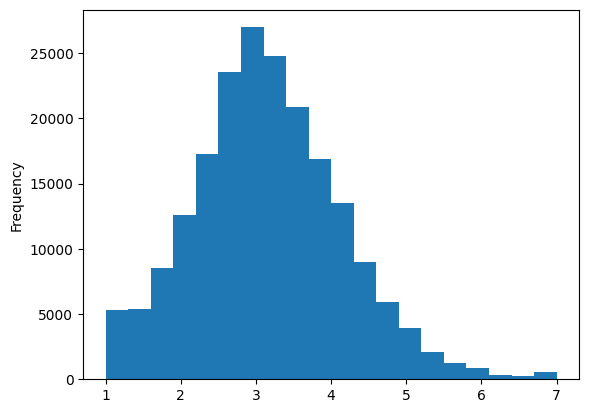

In [46]:
_df.sum(axis=1).clip(0, 7).plot.hist(bins=20)

<Axes: ylabel='Frequency'>

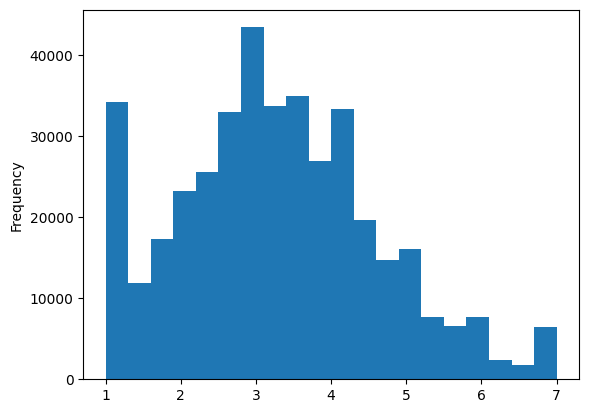

In [49]:
pd.read_csv(next(step1_dir.iterdir()), nrows=400_000).set_index("work_id").sum(
    axis=1
).clip(0, 7).plot.hist(bins=20)